# Redes Neuronales V — Parte 2
### Red neuronal siamesa con Triplet Loss en PyTorch: verificación, identificación y one-shot / few-shot / zero-shot

---

**Universidad de Cundinamarca**

**CADI:** Deep Learning — Conceptos

**Estudiante:** Ruby Dayana Cárdenas Gómez

**Docente:** Nidia Stella García Roa

**Repositorio GitHub:** `https://github.com/RubyDayana/redes-neuronales-v.git`

---

### ¿Qué se hace en este notebook?

En la Parte 1 se construyó el dataset de rostros (38 rostros alineados de 3 personas). Aquí se entrena una **red
neuronal siamesa** que convierte cada rostro en un vector de 64 números (*embedding*) de modo que **dos fotos de la
misma persona queden cerca y fotos de personas distintas queden lejos**. Se entrena con **Triplet Loss** y se
implementa con **PyTorch**.

Lo que se hace, en orden:

1. Repasar los conceptos: red siamesa, embedding, Triplet Loss, verificación frente a identificación, y
   *one-shot*, *few-shot* y *zero-shot learning*.
2. Dividir el dataset en entrenamiento y prueba (sin mezclar fotos).
3. Implementar la **arquitectura**, la **función de pérdida** (y comprobar que está bien calculada) y el
   **muestreo de tripletas** durante el entrenamiento, con aumento de datos.
4. Entrenar y ver las curvas.
5. **Probar el reconocimiento**: verificación (¿son la misma persona?), identificación (¿quién es?) y ejemplos
   concretos de aciertos y errores.
6. Comparar con dos **referencias** (píxeles crudos y red sin entrenar) para saber si la red realmente aprendió.
7. Repetir el experimento con **10 divisiones distintas** de los datos, porque con 38 fotos un solo resultado
   puede ser pura suerte.
8. Probar **one-shot, few-shot y zero-shot**.
9. Explicar los resultados y sus límites.

### Glosario rápido

| Término | Qué significa aquí |
|---|---|
| **Red siamesa** | Una misma red (mismos pesos) que se aplica a varias imágenes para obtener sus embeddings, que luego se comparan por distancia. |
| **Embedding** | Vector que representa una cara. Aquí tiene 64 números y se normaliza para que tenga longitud 1. |
| **Triplet Loss** | Pérdida que usa tres imágenes: ancla, positiva (misma persona) y negativa (otra persona), y exige que la positiva quede más cerca del ancla que la negativa por un margen. |
| **Verificación** | Dadas dos fotos, decidir si son de la misma persona (1:1). |
| **Identificación** | Dada una foto, decir de quién es entre las personas conocidas (1:N). |
| **AUC / EER** | Medidas de la verificación que no dependen del umbral: el área bajo la curva ROC (1 es perfecto, 0.5 es azar) y la tasa de error donde falsos positivos y falsos negativos se igualan. |

---
## 1. Conceptos clave

### 1.1. Red siamesa y embeddings

Un clasificador normal tiene una salida por clase (por ejemplo, 3 personas) y no sirve para una persona nueva: habría
que reentrenarlo. Una **red siamesa** hace otra cosa: no predice la identidad sino que **aprende una distancia**.
La misma red *f* (con los mismos pesos, de ahí lo de "siamesa") transforma cada imagen en un embedding *f(x)*, y la
decisión se toma comparando embeddings:

- si ‖*f(x₁)* − *f(x₂)*‖ es **menor que un umbral**, se dice que son la misma persona;
- para identificar, se compara con los embeddings de las personas registradas y se elige la más cercana.

Como lo que se aprende es "cómo medir parecido entre caras" y no "quién es quién", la red puede
funcionar con personas que **no vio durante el entrenamiento**. Esa es la razón de ser de las redes siamesas en
reconocimiento facial (Schroff et al., 2015; Koch et al., 2015).

### 1.2. Triplet Loss

Se trabaja con **tripletas**: un **ancla** *a*, una imagen **positiva** *p* (misma persona que el ancla) y una
**negativa** *n* (otra persona). La pérdida pide que el ancla esté más cerca de la positiva que de la negativa, por
lo menos un **margen** *α*:

$$\mathcal{L}(a,p,n) = \max\big(0,\; \lVert f(a)-f(p)\rVert^2 - \lVert f(a)-f(n)\rVert^2 + \alpha \big)$$

Si la tripleta ya cumple la condición (la negativa está al menos α más lejos que la positiva), la pérdida es 0 y no
aporta gradiente; si no, la red se corrige. Con muchas tripletas posibles, la mayoría resulta "fácil" y no enseña nada,
así que se eligen con cuidado (*mining*):

| Tipo de tripleta | Condición | Aporte al entrenamiento |
|---|---|---|
| **Fácil** | la negativa ya está más lejos que la positiva + α | Ninguno (pérdida 0) |
| **Semi-dura** | la negativa está más lejos que la positiva, pero dentro del margen | Útil y estable |
| **Dura** | la negativa está más cerca que la positiva | Muy informativa, pero puede desestabilizar |

En este taller se prueban dos formas de elegirlas dentro de cada lote: **batch-hard** (Hermans et al., 2017), que para cada ancla toma su positiva *más
lejana* y su negativa *más cercana*, y **batch-all**, que usa *todas* las tripletas válidas del lote y promedia las que siguen activas. Más abajo se ve cuál funciona con tan pocos datos.

### 1.3. Verificación, identificación y los "n-shot"

- **Verificación (1:1):** ¿estas dos fotos son de la misma persona? Se mide con AUC, EER y exactitud con un umbral.
- **Identificación (1:N):** ¿de quién es esta foto? Se mide con la exactitud de la identificación.
- **One-shot learning:** reconocer a una persona a partir de **una sola** foto de referencia.
- **Few-shot learning:** igual, pero con **pocas** fotos de referencia (2 a 5).
- **Zero-shot learning:** reconocer a una persona **que la red nunca vio durante el entrenamiento** y sobre la que no se
  hace ningún ajuste de pesos. En este taller se prueba dejando una persona fuera del entrenamiento y comparando
  sus embeddings. (En otros contextos, *zero-shot* significa reconocer clases sin ningún ejemplo, solo con una
  descripción; aquí se usa el sentido habitual en reconocimiento facial.)

### 1.4. El papel del preprocesamiento

En la Parte 1 se detectó, alineó y recortó cada rostro. Eso es lo que hace que la comparación sea de **caras** y no
de fondos o ropa. Además, aquí se normalizan los píxeles y se usa **aumento de datos** (giros, recortes, cambios de
brillo, color), porque con 38 fotos la red memorizaría el conjunto de entrenamiento si siempre viera las mismas
imágenes.

In [1]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision.transforms import v2
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(2)
DISPOSITIVO = "cpu"            # el modelo es pequeño; en CPU entrena en segundos
print("PyTorch", torch.__version__, "| dispositivo:", DISPOSITIVO)

TAM = 64                       # los rostros de 112 x 112 se reducen a 64 x 64 para entrenar rápido

def cargar_rostros(carpeta="datos/rostros", tam=TAM):
    """Lee los recortes de la Parte 1. Devuelve imágenes (N, tam, tam, 3), etiquetas y nombres de las personas."""
    X, y = [], []
    personas = sorted(d for d in os.listdir(carpeta) if os.path.isdir(f"{carpeta}/{d}"))
    for k, p in enumerate(personas):
        for f in sorted(glob.glob(f"{carpeta}/{p}/*.png")):
            X.append(np.asarray(Image.open(f).convert("RGB").resize((tam, tam), Image.LANCZOS)))
            y.append(k)
    return np.stack(X), np.array(y), personas

X, y, PERSONAS = cargar_rostros()
print("Imágenes:", X.shape, "| personas:", PERSONAS, "| fotos por persona:", np.bincount(y).tolist())

PyTorch 2.14.1+cu130 | dispositivo: cpu
Imágenes: (38, 64, 64, 3) | personas: ['ayis', 'gaby', 'yeyo'] | fotos por persona: [17, 7, 14]


## 2. División en entrenamiento y prueba

Con tan pocas fotos, la división debe cuidarse: se separa **aproximadamente el 35 % de las fotos de cada persona
para prueba** (estratificado, para que todas las personas estén en ambos conjuntos) y el resto para entrenamiento.
La red **nunca ve las fotos de prueba** durante el entrenamiento: sirven para saber si reconoce fotos nuevas de las
mismas personas y no solo las que memorizó.

Como 38 fotos son pocas, un solo reparto puede salir bien o mal por suerte. Por eso la función recibe una
**semilla** y más adelante se repite todo con 10 repartos distintos.

In [2]:
def dividir(y, semilla, frac_test=0.35):
    """Reparto estratificado: devuelve índices de entrenamiento y de prueba."""
    rng = np.random.RandomState(semilla)
    tr, te = [], []
    for k in np.unique(y):
        idx = rng.permutation(np.where(y == k)[0])
        n_te = max(1, int(round(frac_test * len(idx))))
        te += idx[:n_te].tolist(); tr += idx[n_te:].tolist()
    return np.array(sorted(tr)), np.array(sorted(te))

tr, te = dividir(y, semilla=0)
tabla = pd.DataFrame({"persona": PERSONAS, "total": np.bincount(y),
                      "entrenamiento": np.bincount(y[tr], minlength=len(PERSONAS)),
                      "prueba": np.bincount(y[te], minlength=len(PERSONAS))}).set_index("persona")
print(tabla.to_string())
print("\nTotal entrenamiento:", len(tr), "| total prueba:", len(te))

         total  entrenamiento  prueba
persona                              
ayis        17             11       6
gaby         7              5       2
yeyo        14              9       5

Total entrenamiento: 25 | total prueba: 13


## 3. La red, la pérdida y el muestreo de tripletas

### 3.1. Arquitectura

Es una red convolucional pequeña, adecuada para el tamaño del dataset (≈250 000 parámetros):

| Parte | Capas | Tamaño de salida |
|---|---|---|
| Entrada | imagen RGB normalizada | 3 × 64 × 64 |
| Bloque 1 | Conv 3×3 (32) → BatchNorm → ReLU → MaxPool | 32 × 32 × 32 |
| Bloque 2 | Conv 3×3 (64) → BatchNorm → ReLU → MaxPool | 64 × 16 × 16 |
| Bloque 3 | Conv 3×3 (128) → BatchNorm → ReLU → MaxPool | 128 × 8 × 8 |
| Bloque 4 | Conv 3×3 (128) → BatchNorm → ReLU → MaxPool | 128 × 4 × 4 |
| Cabeza | Promedio global → Dropout 0.3 → Lineal (64) → **normalización L2** | vector de 64 con norma 1 |

Cada imagen pasa por **la misma red** (pesos compartidos), que es lo que la hace siamesa. La normalización L2
final deja todos los embeddings sobre una esfera de radio 1, así que la distancia al cuadrado entre dos embeddings
está entre 0 y 4 y no se puede "hacer trampa" agrandando los vectores.

In [3]:
class RedSiamesa(nn.Module):
    """CNN que convierte un rostro en un embedding de `dim` números con norma 1."""
    def __init__(self, dim=64):
        super().__init__()
        def bloque(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.cuerpo = nn.Sequential(bloque(3, 32), bloque(32, 64), bloque(64, 128), bloque(128, 128))
        self.cabeza = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, dim))

    def forward(self, x):
        return F.normalize(self.cabeza(self.cuerpo(x)), dim=1)

modelo_demo = RedSiamesa()
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo_demo.parameters() if p.requires_grad):,}")
salida = modelo_demo.eval()(torch.randn(5, 3, TAM, TAM))
print("Salida para 5 imágenes:", tuple(salida.shape), "| normas:", salida.norm(dim=1).detach().numpy().round(3))

Parámetros entrenables: 249,440
Salida para 5 imágenes: (5, 64) | normas: [1. 1. 1. 1. 1.]


### 3.2. Triplet Loss, implementada a mano

Primero la fórmula para tripletas dadas. Antes de usarla se comprueba contra la implementación de PyTorch
(`nn.TripletMarginLoss`) con las mismas tripletas, para asegurar que está bien escrita, y se calcula a mano un ejemplo
de cada tipo de tripleta (fácil, semi-dura y dura).

In [4]:
def triplet_loss(ancla, pos, neg, margen, al_cuadrado=True):
    """Triplet Loss de FaceNet: max(0, d(a,p) - d(a,n) + margen), con d = distancia euclídea (al cuadrado por defecto)."""
    d_ap = (ancla - pos).pow(2).sum(1)
    d_an = (ancla - neg).pow(2).sum(1)
    if not al_cuadrado:
        d_ap, d_an = d_ap.sqrt(), d_an.sqrt()
    return F.relu(d_ap - d_an + margen).mean()

# Comprobación contra PyTorch (que usa la distancia sin elevar al cuadrado)
torch.manual_seed(0)
a, p, n = (F.normalize(torch.randn(32, 64), dim=1) for _ in range(3))
propia = triplet_loss(a, p, n, margen=0.3, al_cuadrado=False).item()
de_torch = nn.TripletMarginLoss(margin=0.3, p=2, eps=0.0)(a, p, n).item()
print(f"Triplet Loss propia      : {propia:.6f}")
print(f"nn.TripletMarginLoss     : {de_torch:.6f}")
print(f"Diferencia absoluta      : {abs(propia - de_torch):.2e}")
print()

# Ejemplo numérico a mano: una tripleta fácil, una semi-dura y una dura (embeddings en 2D, margen 0.3)
ancla = torch.tensor([[1.0, 0.0]] * 3)
pos   = torch.tensor([[0.98, 0.199], [0.98, 0.199], [0.8, 0.6]])
neg   = torch.tensor([[-1.0, 0.0], [0.9, 0.436], [0.95, 0.312]])
for nombre, i in zip(["fácil", "semi-dura", "dura"], range(3)):
    d_ap = (ancla[i] - pos[i]).pow(2).sum().item(); d_an = (ancla[i] - neg[i]).pow(2).sum().item()
    print(f"Tripleta {nombre:9s}: d(a,p)={d_ap:.3f}  d(a,n)={d_an:.3f}  pérdida = max(0, {d_ap:.3f} - {d_an:.3f} + 0.3) = {max(0, d_ap - d_an + 0.3):.3f}")

Triplet Loss propia      : 0.274137
nn.TripletMarginLoss     : 0.274137
Diferencia absoluta      : 0.00e+00

Tripleta fácil    : d(a,p)=0.040  d(a,n)=4.000  pérdida = max(0, 0.040 - 4.000 + 0.3) = 0.000
Tripleta semi-dura: d(a,p)=0.040  d(a,n)=0.200  pérdida = max(0, 0.040 - 0.200 + 0.3) = 0.140
Tripleta dura     : d(a,p)=0.400  d(a,n)=0.100  pérdida = max(0, 0.400 - 0.100 + 0.3) = 0.600


### 3.3. Cómo se eligen las tripletas dentro de un lote

En cada paso se arma un lote con **6 fotos de cada persona** de entrenamiento (así siempre hay positivas y
negativas). Con los embeddings de ese lote se calculan las distancias entre todas las parejas y se forman tripletas
de dos maneras:

- **Batch-hard:** para cada ancla, solo la positiva más lejana y la negativa más cercana.
- **Batch-all:** todas las tripletas (ancla, positiva, negativa) posibles del lote; la pérdida es el promedio de las que
  siguen activas (pérdida > 0). Así no se desperdician las tripletas fáciles en el promedio.

Las dos devuelven también la **fracción de tripletas activas**, un indicador de cuánto le falta aprender a la red.

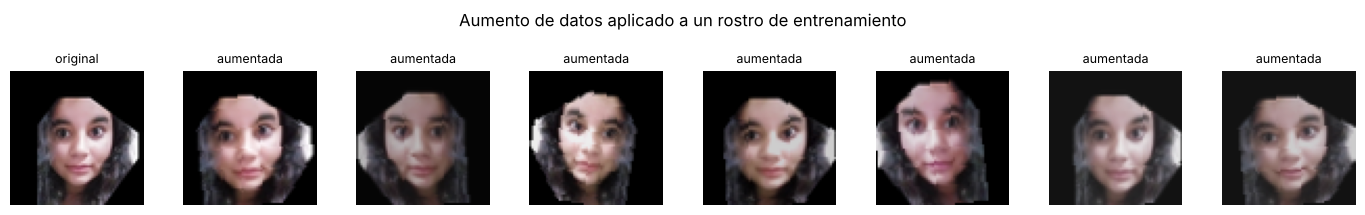

In [5]:
def perdida_batch_hard(emb, etiquetas, margen):
    """Para cada ancla: positiva más lejana y negativa más cercana dentro del lote. Devuelve (pérdida, fracción activa)."""
    d = torch.cdist(emb, emb).pow(2)
    misma = etiquetas[:, None] == etiquetas[None, :]
    yo = torch.eye(len(etiquetas), dtype=torch.bool)
    d_pos = d.masked_fill(~misma | yo, float("-inf")).max(1).values
    d_neg = d.masked_fill(misma, float("inf")).min(1).values
    perdida = F.relu(d_pos - d_neg + margen)
    return perdida.mean(), (perdida > 0).float().mean()

def perdida_batch_all(emb, etiquetas, margen):
    """Todas las tripletas válidas del lote; la pérdida es el promedio de las que siguen activas."""
    d = torch.cdist(emb, emb).pow(2)
    misma = etiquetas[:, None] == etiquetas[None, :]
    yo = torch.eye(len(etiquetas), dtype=torch.bool)
    valida = (misma & ~yo)[:, :, None] & (~misma)[:, None, :]            # (ancla, positiva, negativa)
    perdida = F.relu(d[:, :, None] - d[:, None, :] + margen) * valida
    activas = (perdida > 0).float().sum()
    return perdida.sum() / activas.clamp(min=1), activas / valida.sum()

PERDIDAS = {"hard": perdida_batch_hard, "all": perdida_batch_all}

def muestrear_lote(y_tr, rng, K=6):
    """Lote 'P personas x K fotos': K fotos de cada persona de entrenamiento."""
    idx = []
    for k in np.unique(y_tr):
        pool = np.where(y_tr == k)[0]
        idx += rng.choice(pool, size=K, replace=len(pool) < K).tolist()
    return np.array(idx)

# Aumento de datos: giro, recorte, rotación pequeña, cambios de brillo/contraste/color y a veces gris
aumento = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomResizedCrop(TAM, scale=(0.75, 1.0), ratio=(0.9, 1.1), antialias=True),
    v2.RandomRotation(10),
    v2.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3, hue=0.03),
    v2.RandomGrayscale(p=0.1),
])

def a_tensor(imgs_uint8):
    """(N, H, W, 3) uint8 -> (N, 3, H, W) float normalizado con constantes fijas (no usa datos de prueba)."""
    t = torch.from_numpy(imgs_uint8).permute(0, 3, 1, 2).float() / 255
    return (t - 0.5) / 0.25

# Vista previa del aumento sobre un mismo rostro
torch.manual_seed(1)
base = torch.from_numpy(X[tr[0]]).permute(2, 0, 1)
fig, ejes = plt.subplots(1, 8, figsize=(14, 2))
ejes[0].imshow(X[tr[0]]); ejes[0].set_title("original", fontsize=9)
for e in ejes[1:]:
    e.imshow(aumento(base).permute(1, 2, 0).numpy()); e.set_title("aumentada", fontsize=9)
for e in ejes: e.axis("off")
plt.suptitle("Aumento de datos aplicado a un rostro de entrenamiento", y=1.05); plt.tight_layout(); plt.show()

### 3.4. Entrenamiento

Se entrena con el optimizador **AdamW** (tasa de aprendizaje 0.002 con decaimiento coseno, *weight decay* 1e-4)
durante 300 pasos, con **margen 0.3**. En cada paso: se arma el lote, se le aplica aumento de datos, se calculan los
embeddings y se aplica la pérdida elegida.

Se entrenan **las dos variantes con el mismo reparto de datos** para compararlas. Para saber si la red está
aprendiendo se mide también la **dispersión de los embeddings** (desviación estándar media por dimensión): si
todos los rostros terminan con el mismo embedding (un *colapso*), la dispersión es casi 0; con embeddings bien
repartidos en la esfera de 64 dimensiones se espera algo cercano a 1/√64 = 0.125.

=== Triplet Loss con batch-hard ===


  paso   75  pérdida 0.3543  tripletas activas 100.0 %


  paso  150  pérdida 0.3102  tripletas activas 100.0 %


  paso  225  pérdida 0.3081  tripletas activas 100.0 %


  paso  300  pérdida 0.3072  tripletas activas 100.0 %
  tiempo 24 s | dispersión de los embeddings: 0.006  (esperado si no hay colapso: ~0.125)

=== Triplet Loss con batch-all ===


  paso   75  pérdida 0.3177  tripletas activas  38.6 %


  paso  150  pérdida 0.3056  tripletas activas  16.2 %


  paso  225  pérdida 0.2938  tripletas activas   7.9 %


  paso  300  pérdida 0.2162  tripletas activas   2.6 %
  tiempo 23 s | dispersión de los embeddings: 0.103  (esperado si no hay colapso: ~0.125)



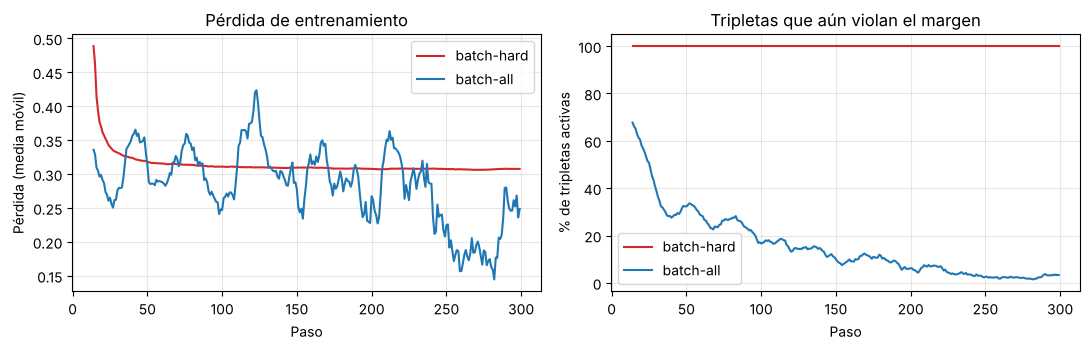

In [6]:
def entrenar(X_tr, y_tr, semilla=0, pasos=300, margen=0.3, dim=64, lr=2e-3, mineria="all", verbose=False):
    """Entrena la red siamesa con Triplet Loss. Devuelve el modelo (en modo evaluación) y el historial."""
    torch.manual_seed(semilla); rng = np.random.RandomState(semilla)
    modelo = RedSiamesa(dim)
    opt = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=pasos)
    perdida_fn = PERDIDAS[mineria]
    X_t = torch.from_numpy(X_tr).permute(0, 3, 1, 2)
    historial = {"perdida": [], "activas": []}
    for paso in range(pasos):
        modelo.train()
        idx = muestrear_lote(y_tr, rng)
        lote = (torch.stack([aumento(X_t[i]) for i in idx]).float() / 255 - 0.5) / 0.25
        perdida, activas = perdida_fn(modelo(lote), torch.from_numpy(y_tr[idx]), margen)
        opt.zero_grad(); perdida.backward(); opt.step(); sched.step()
        historial["perdida"].append(perdida.item()); historial["activas"].append(activas.item())
        if verbose and (paso + 1) % 75 == 0:
            print(f"  paso {paso + 1:4d}  pérdida {np.mean(historial['perdida'][-75:]):.4f}  tripletas activas {np.mean(historial['activas'][-75:]) * 100:5.1f} %")
    return modelo.eval(), historial

@torch.no_grad()
def incrustar(modelo, imgs_uint8):
    """Embeddings (sin aumento) de un conjunto de imágenes."""
    modelo.eval()
    return modelo(a_tensor(imgs_uint8)).numpy()

dispersion = lambda emb: float(emb.std(axis=0).mean())

modelos, hists = {}, {}
for mineria in ["hard", "all"]:
    t0 = time.time()
    print(f"=== Triplet Loss con batch-{mineria} ===")
    modelos[mineria], hists[mineria] = entrenar(X[tr], y[tr], semilla=0, mineria=mineria, verbose=True)
    e = incrustar(modelos[mineria], X)
    print(f"  tiempo {time.time() - t0:.0f} s | dispersión de los embeddings: {dispersion(e):.3f}  (esperado si no hay colapso: ~0.125)\n")

modelo = modelos["all"]                      # modelo principal del resto del notebook
os.makedirs("modelos", exist_ok=True)
torch.save(modelo.state_dict(), "modelos/siamesa_pytorch.pt")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
suave = lambda v, w=15: np.convolve(v, np.ones(w) / w, mode="valid")
for mineria, color in [("hard", "tab:red"), ("all", "tab:blue")]:
    ejes[0].plot(range(14, 300), suave(hists[mineria]["perdida"]), color=color, label=f"batch-{mineria}")
    ejes[1].plot(range(14, 300), suave(np.array(hists[mineria]["activas"]) * 100), color=color, label=f"batch-{mineria}")
ejes[0].set(xlabel="Paso", ylabel="Pérdida (media móvil)", title="Pérdida de entrenamiento"); ejes[0].legend()
ejes[1].set(xlabel="Paso", ylabel="% de tripletas activas", title="Tripletas que aún violan el margen"); ejes[1].legend()
plt.tight_layout(); plt.show()

**Lectura del entrenamiento.** Las dos variantes de Triplet Loss se comportan de manera muy distinta con el mismo reparto de datos:

- **Batch-hard colapsa.** La pérdida se queda en 0.307, que es casi exactamente el margen (0.3), el 100 % de las tripletas
  siguen activas y la dispersión de los embeddings es de apenas 0.006. Es el síntoma clásico del **colapso**: la red
  aprende a dar el mismo embedding a todos los rostros. Entonces d(a,p) = d(a,n) = 0 y cada tripleta tiene pérdida igual al margen,
  sin posibilidad de mejorar. Con tan pocas fotos y una red entrenada desde cero, elegir solo las tripletas más duras
  al principio empuja la red hacia esa solución trivial.
- **Batch-all aprende.** La pérdida baja a 0.216 y las tripletas activas pasan de 100 % al principio a 38.6 %, 16.2 %, 7.9 % y 2.6 %
  al final de cada tramo de 75 pasos. La dispersión es de 0.103, cercana al valor esperado de 0.125.

Por eso el resto del taller usa **batch-all**. El 2.6 % de tripletas activas al final también indica que la red ya casi
no se equivoca *en el conjunto de entrenamiento*; si eso se traduce en buen desempeño con fotos nuevas es lo que se mide a continuación.

## 4. Pruebas de reconocimiento facial

Todas las pruebas usan **fotos de prueba** que la red nunca vio durante el entrenamiento.

### 4.1. Funciones de evaluación

- **Verificación:** se forman todas las parejas de fotos de prueba (las del mismo individuo son pares positivos, el resto
  negativos), se mide su distancia y se calculan el **AUC** y el **EER**. Para la exactitud con un umbral concreto, el
  umbral se elige con los pares de **entrenamiento**, nunca con los de prueba. Se reporta la **exactitud balanceada** (promedio
  del acierto en pares iguales y en pares distintos), porque hay muchos más pares distintos que iguales.
- **Identificación:** cada persona registrada se representa por el promedio de sus embeddings de entrenamiento (un
  *prototipo*) y cada foto de prueba se asigna al prototipo más cercano. Se reporta la **exactitud balanceada** (promedio del
  acierto por persona; con 3 personas, el azar es 33 %).

In [7]:
from sklearn.metrics import balanced_accuracy_score

def pares(etiquetas):
    i, j = np.triu_indices(len(etiquetas), 1)
    return i, j, etiquetas[i] == etiquetas[j]

def distancias(emb, i, j):
    return ((emb[i] - emb[j]) ** 2).sum(1)

def tasa_igual_error(misma, puntaje):
    fpr, tpr, _ = roc_curve(misma, puntaje)
    fnr = 1 - tpr
    k = int(np.nanargmin(np.abs(fnr - fpr)))
    return float((fpr[k] + fnr[k]) / 2)

def verificacion(emb, y_, tr_idx, te_idx):
    i, j, misma = pares(y_[te_idx]); d = distancias(emb[te_idx], i, j)
    # umbral elegido SOLO con pares de entrenamiento
    itr, jtr, mtr = pares(y_[tr_idx]); dtr = distancias(emb[tr_idx], itr, jtr)
    cand = np.linspace(0, 4, 401)
    bal_tr = [(np.mean(dtr[mtr] < u) + np.mean(dtr[~mtr] >= u)) / 2 for u in cand]
    u = float(cand[int(np.argmax(bal_tr))])
    pred = d < u
    return {"auc": roc_auc_score(misma, -d), "eer": tasa_igual_error(misma, -d), "umbral": u,
            "acc_bal": (np.mean(pred[misma]) + np.mean(~pred[~misma])) / 2,
            "pares": len(misma), "pares_iguales": int(misma.sum())}

def prototipos(emb_ref, y_ref):
    clases = np.unique(y_ref)
    P = np.stack([emb_ref[y_ref == k].mean(0) for k in clases])
    return clases, P / np.linalg.norm(P, axis=1, keepdims=True)

def identificar(emb_ref, y_ref, emb_q):
    clases, P = prototipos(emb_ref, y_ref)
    return clases[(emb_q @ P.T).argmax(1)]

def identificacion(emb, y_, tr_idx, te_idx):
    pred = identificar(emb[tr_idx], y_[tr_idx], emb[te_idx])
    return {"acc_bal": balanced_accuracy_score(y_[te_idx], pred), "acc": float(np.mean(pred == y_[te_idx])), "pred": pred}

# Referencias para saber si la red realmente aprendió
def emb_pixeles(imgs):
    """Referencia 1: píxeles crudos (gris 32x32, normalizados). No hay red."""
    g = np.stack([np.asarray(Image.fromarray(im).convert("L").resize((32, 32))) for im in imgs]).reshape(len(imgs), -1).astype(float)
    g = g - g.mean(1, keepdims=True)
    return g / np.linalg.norm(g, axis=1, keepdims=True)

def emb_red_sin_entrenar(imgs, semilla=0):
    """Referencia 2: la misma arquitectura con pesos aleatorios, sin entrenar."""
    torch.manual_seed(semilla)
    return incrustar(RedSiamesa().eval(), imgs)

EMBS = {"Píxeles crudos": emb_pixeles(X), "Red sin entrenar": emb_red_sin_entrenar(X),
        "Siamesa (batch-hard)": incrustar(modelos["hard"], X), "Siamesa (batch-all)": incrustar(modelos["all"], X)}

filas = []
for nombre, emb in EMBS.items():
    v, ident = verificacion(emb, y, tr, te), identificacion(emb, y, tr, te)
    filas.append({"Modelo": nombre, "AUC": v["auc"], "EER": v["eer"], "Exactitud verif. (balanceada)": v["acc_bal"],
                  "Exactitud identif. (balanceada)": ident["acc_bal"]})
comparacion = pd.DataFrame(filas).set_index("Modelo")
print(f"Reparto 0: {v['pares']} pares de prueba ({v['pares_iguales']} de la misma persona)")
comparacion.round(3)

Reparto 0: 78 pares de prueba (26 de la misma persona)


,AUC,EER,Exactitud verif. (balanceada),Exactitud identif. (balanceada)
Modelo,,,,
Píxeles crudos,0.488,0.529,0.519,0.689
Red sin entrenar,0.496,0.500,0.481,0.522
Siamesa (batch-hard),0.704,0.385,0.606,0.589
Siamesa (batch-all),0.823,0.288,0.750,0.889


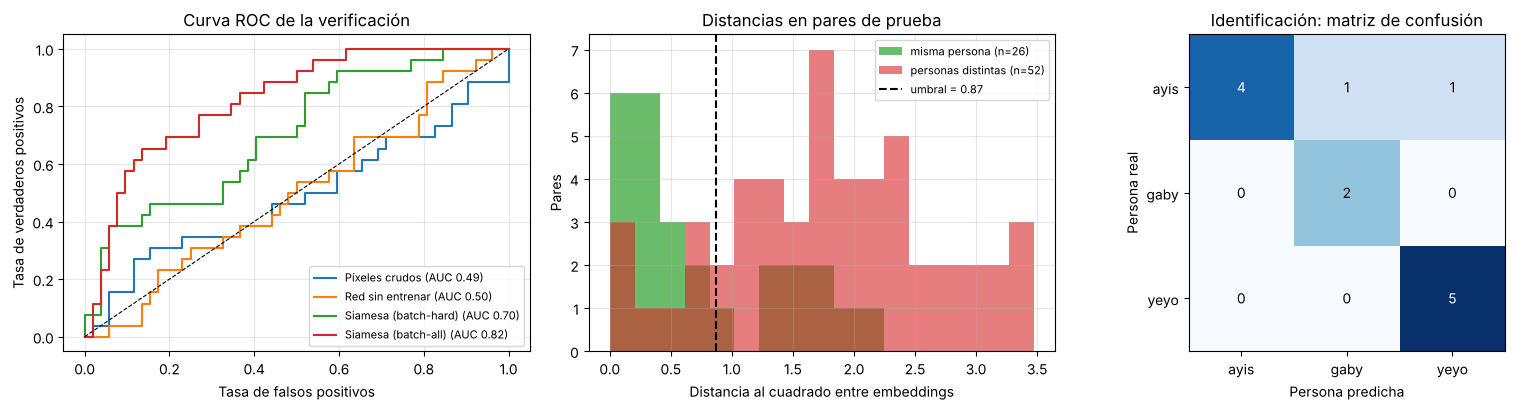

In [8]:
# Curvas ROC y distribución de distancias de la red entrenada (reparto 0, fotos de prueba)
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.2))
i, j, misma = pares(y[te])
for nombre, emb in EMBS.items():
    d = distancias(emb[te], i, j)
    fpr, tpr, _ = roc_curve(misma, -d)
    ejes[0].plot(fpr, tpr, label=f"{nombre} (AUC {roc_auc_score(misma, -d):.2f})")
ejes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ejes[0].set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title="Curva ROC de la verificación"); ejes[0].legend(fontsize=8)

emb_p = EMBS["Siamesa (batch-all)"]
d = distancias(emb_p[te], i, j)
bins = np.linspace(0, max(d.max(), 1.0), 18)
ejes[1].hist(d[misma], bins, alpha=0.7, label=f"misma persona (n={misma.sum()})", color="tab:green")
ejes[1].hist(d[~misma], bins, alpha=0.6, label=f"personas distintas (n={(~misma).sum()})", color="tab:red")
umbral = verificacion(emb_p, y, tr, te)["umbral"]
ejes[1].axvline(umbral, color="k", ls="--", label=f"umbral = {umbral:.2f}")
ejes[1].set(xlabel="Distancia al cuadrado entre embeddings", ylabel="Pares", title="Distancias en pares de prueba"); ejes[1].legend(fontsize=8)

# Matriz de confusión de la identificación
ident = identificacion(emb_p, y, tr, te)
cm = confusion_matrix(y[te], ident["pred"], labels=range(len(PERSONAS)))
ejes[2].imshow(cm, cmap="Blues"); ejes[2].grid(False)
for a in range(cm.shape[0]):
    for b in range(cm.shape[1]):
        ejes[2].text(b, a, cm[a, b], ha="center", va="center", color="white" if cm[a, b] > cm.max() / 2 else "black")
ejes[2].set(xticks=range(len(PERSONAS)), yticks=range(len(PERSONAS)), xticklabels=PERSONAS, yticklabels=PERSONAS,
            xlabel="Persona predicha", ylabel="Persona real", title="Identificación: matriz de confusión")
plt.tight_layout(); plt.show()

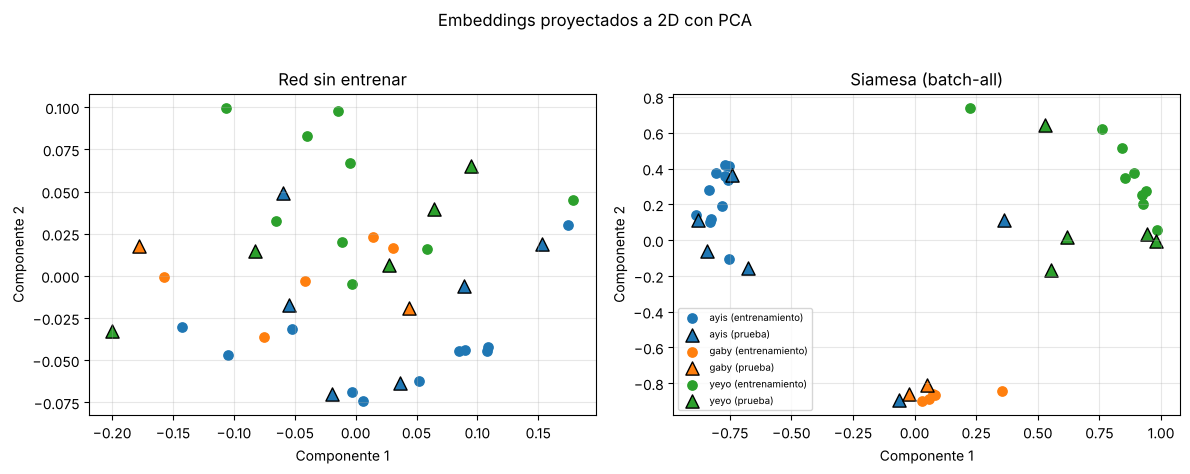

In [9]:
# Los embeddings en 2D (PCA): ¿se agrupan por persona? Entrenamiento (círculos) y prueba (triángulos)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.6))
colores = ["tab:blue", "tab:orange", "tab:green"]
for eje, nombre in zip(ejes, ["Red sin entrenar", "Siamesa (batch-all)"]):
    emb = EMBS[nombre]; proy = PCA(2, random_state=0).fit_transform(emb)
    for k, p in enumerate(PERSONAS):
        m_tr, m_te = (y == k) & np.isin(np.arange(len(y)), tr), (y == k) & np.isin(np.arange(len(y)), te)
        eje.scatter(*proy[m_tr].T, c=colores[k], marker="o", s=45, label=f"{p} (entrenamiento)")
        eje.scatter(*proy[m_te].T, c=colores[k], marker="^", s=90, edgecolor="k", label=f"{p} (prueba)")
    eje.set_title(nombre); eje.set_xlabel("Componente 1"); eje.set_ylabel("Componente 2")
ejes[1].legend(fontsize=7, loc="best")
plt.suptitle("Embeddings proyectados a 2D con PCA", y=1.02); plt.tight_layout(); plt.show()

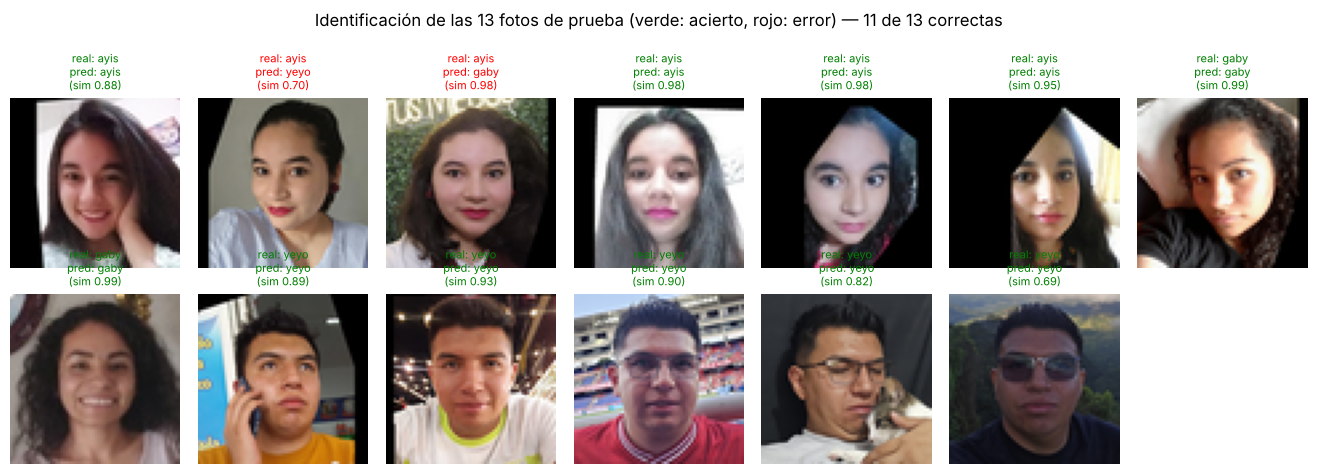

In [10]:
# Evidencia de ejecución: cada foto de prueba, su persona real y lo que predice el modelo
pred = ident["pred"]
n = len(te)
fig, ejes = plt.subplots(2, int(np.ceil(n / 2)), figsize=(1.9 * int(np.ceil(n / 2)), 4.6))
sim_all = emb_p[te] @ prototipos(emb_p[tr], y[tr])[1].T
for k, (eje, idx) in enumerate(zip(ejes.ravel(), te)):
    ok = pred[k] == y[idx]
    eje.imshow(X[idx]); eje.axis("off")
    eje.set_title(f"real: {PERSONAS[y[idx]]}\npred: {PERSONAS[pred[k]]}\n(sim {sim_all[k].max():.2f})", fontsize=8, color="green" if ok else "red")
for eje in ejes.ravel()[n:]: eje.axis("off")
plt.suptitle(f"Identificación de las {n} fotos de prueba (verde: acierto, rojo: error) — {int((pred == y[te]).sum())} de {n} correctas", y=1.02)
plt.tight_layout(); plt.show()

**Lectura de las pruebas (reparto 0).** En las 13 fotos de prueba (78 pares, 26 de la misma persona):

- **Verificación.** La siamesa con batch-all logra un **AUC de 0.823** y un EER de 0.288: si se escoge al azar un par de la
  misma persona y uno de personas distintas, el de la misma persona está más cerca en el 82 % de los casos. Con el umbral
  elegido con los pares de entrenamiento (0.87) la exactitud balanceada es **0.750**. Las dos referencias no aprenden nada: los
  píxeles crudos dan un AUC de 0.488 y la red sin entrenar 0.496, es decir, azar (0.5). La variante batch-hard colapsada llega a 0.704,
  algo por encima del azar pero muy por debajo de batch-all.
- **Identificación.** Con prototipos por persona, la siamesa identifica **11 de las 13 fotos** (exactitud balanceada 0.889): acierta las
  5 de yeyo y las 2 de gaby y se equivoca en 2 de las 6 de ayis (una la confunde con gaby y otra con yeyo). Aquí los píxeles crudos
  llegan a 0.689, lo que es sorprendentemente alto y tiene explicación: varias fotos de una misma persona comparten fondo,
  iluminación o color de ropa, que los píxeles capturan.
- **Embeddings en 2D.** Con la red sin entrenar los puntos de las tres personas se mezclan; con la red entrenada se ven
  agrupados por persona, y las fotos de prueba (triángulos) caen cerca de su grupo en la mayoría de los casos.

Un solo reparto con 13 fotos de prueba no permite sacar conclusiones, por eso se repite 10 veces.

## 5. Repetir el experimento con 10 repartos distintos

Un solo reparto de 38 fotos puede dar un resultado bueno o malo por suerte (¡cuál foto cayó en prueba!). Para tener una
idea más honesta, se repite **todo** (reparto, entrenamiento y evaluación) con 10 semillas distintas y se reporta el
promedio y la desviación estándar. En la misma corrida se evalúa también el **one-shot** y el **few-shot**:

- **One-shot:** cada persona se registra con **una sola foto** de entrenamiento elegida al azar (30 sorteos por
  reparto) y se identifican las fotos de prueba comparándolas con esa única referencia.
- **Few-shot:** lo mismo con 2, 3 y 5 fotos de referencia por persona.

En ningún caso se reentrena la red: solo se cambian las fotos de referencia con las que se compara.

In [11]:
def n_shot(emb, y_, tr_idx, te_idx, k, rng, sorteos=30):
    """Identificación registrando a cada persona con k fotos de referencia elegidas al azar entre las de entrenamiento."""
    accs = []
    for _ in range(sorteos):
        ref = []
        for c in np.unique(y_):
            pool = tr_idx[y_[tr_idx] == c]
            ref += rng.choice(pool, size=min(k, len(pool)), replace=False).tolist()
        ref = np.array(ref)
        accs.append(balanced_accuracy_score(y_[te_idx], identificar(emb[ref], y_[ref], emb[te_idx])))
    return float(np.mean(accs))

SEMILLAS = list(range(10))
KS = [1, 2, 3, 5]
filas = []
t0 = time.time()
for s in SEMILLAS:
    tr_s, te_s = dividir(y, s)
    m_s, _ = entrenar(X[tr_s], y[tr_s], semilla=s, mineria="all")
    embs = {"Píxeles crudos": EMBS["Píxeles crudos"], "Red sin entrenar": emb_red_sin_entrenar(X, semilla=s), "Siamesa": incrustar(m_s, X)}
    rng = np.random.RandomState(100 + s)
    for nombre, emb in embs.items():
        v, ident_s = verificacion(emb, y, tr_s, te_s), identificacion(emb, y, tr_s, te_s)
        fila = {"semilla": s, "modelo": nombre, "auc": v["auc"], "eer": v["eer"], "verif_acc_bal": v["acc_bal"], "ident_acc_bal": ident_s["acc_bal"]}
        for k in KS:
            fila[f"{k}-shot"] = n_shot(emb, y, tr_s, te_s, k, rng)
        filas.append(fila)
    print(f"reparto {s}: AUC siamesa {filas[-1]['auc']:.3f} | identificación {filas[-1]['ident_acc_bal']:.3f} | {time.time() - t0:.0f} s")
res = pd.DataFrame(filas)
os.makedirs("resultados", exist_ok=True)
res.to_csv("resultados/pytorch_repartos.csv", index=False)

reparto 0: AUC siamesa 0.823 | identificación 0.889 | 23 s


reparto 1: AUC siamesa 0.796 | identificación 0.556 | 46 s


reparto 2: AUC siamesa 0.702 | identificación 0.589 | 68 s


reparto 3: AUC siamesa 0.766 | identificación 0.822 | 90 s


reparto 4: AUC siamesa 0.777 | identificación 0.600 | 114 s


reparto 5: AUC siamesa 0.910 | identificación 0.711 | 138 s


reparto 6: AUC siamesa 0.604 | identificación 0.689 | 160 s


reparto 7: AUC siamesa 0.831 | identificación 0.611 | 183 s


reparto 8: AUC siamesa 0.740 | identificación 0.811 | 206 s


reparto 9: AUC siamesa 0.774 | identificación 0.544 | 228 s


Promedio y desviación estándar en 10 repartos (fotos de prueba)
                    auc           eer        verif_acc_bal        ident_acc_bal       
                   mean    std   mean    std          mean    std          mean    std
modelo                                                                                
Píxeles crudos    0.615  0.119  0.408  0.098         0.580  0.089         0.629  0.161
Red sin entrenar  0.638  0.089  0.384  0.077         0.562  0.064         0.569  0.197
Siamesa           0.772  0.082  0.299  0.094         0.694  0.087         0.682  0.123

Repartos en los que la siamesa supera en AUC a:  píxeles crudos -> 8 de 10 |  red sin entrenar -> 9 de 10

Identificación (exactitud balanceada) según cuántas fotos de referencia hay por persona (azar = 0.333)
          Píxeles crudos Red sin entrenar        Siamesa
1 foto(s)  0.489 ± 0.055    0.502 ± 0.086  0.704 ± 0.110
2 foto(s)  0.536 ± 0.062    0.528 ± 0.111  0.702 ± 0.114
3 foto(s)  0.575 ± 0.066    0.55

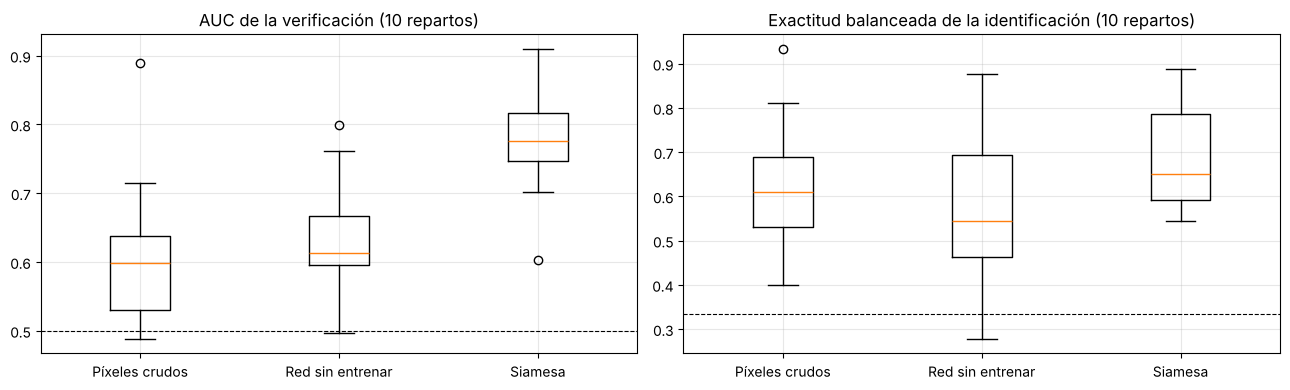

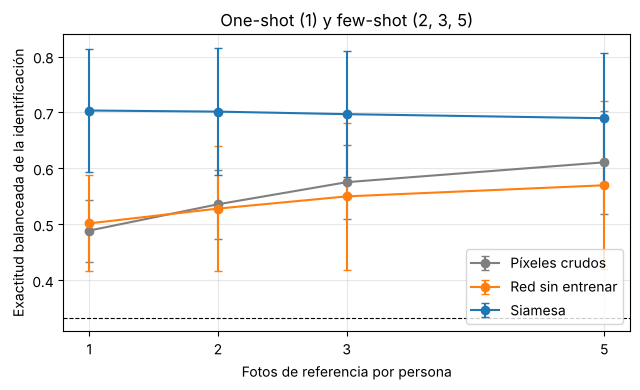

In [12]:
resumen = res.groupby("modelo")[["auc", "eer", "verif_acc_bal", "ident_acc_bal"]].agg(["mean", "std"]).round(3)
resumen = resumen.loc[["Píxeles crudos", "Red sin entrenar", "Siamesa"]]
print("Promedio y desviación estándar en 10 repartos (fotos de prueba)")
print(resumen.to_string())

sia, base_px, base_red = (res[res.modelo == m].set_index("semilla") for m in ["Siamesa", "Píxeles crudos", "Red sin entrenar"])
print()
print("Repartos en los que la siamesa supera en AUC a:  píxeles crudos ->", int((sia.auc > base_px.auc).sum()), "de 10 |  red sin entrenar ->", int((sia.auc > base_red.auc).sum()), "de 10")

# One-shot y few-shot
nshot = res.groupby("modelo")[[f"{k}-shot" for k in KS]].agg(["mean", "std"])
print()
print("Identificación (exactitud balanceada) según cuántas fotos de referencia hay por persona (azar = 0.333)")
tabla_n = pd.DataFrame({m: [f"{nshot.loc[m, (f'{k}-shot', 'mean')]:.3f} ± {nshot.loc[m, (f'{k}-shot', 'std')]:.3f}" for k in KS]
                        for m in ["Píxeles crudos", "Red sin entrenar", "Siamesa"]}, index=[f"{k} foto(s)" for k in KS])
print(tabla_n.to_string())

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
orden = ["Píxeles crudos", "Red sin entrenar", "Siamesa"]
for k, (col, titulo) in enumerate([("auc", "AUC de la verificación"), ("ident_acc_bal", "Exactitud balanceada de la identificación")]):
    datos = [res[res.modelo == m][col].values for m in orden]
    ejes[0 if k == 0 else 1].boxplot(datos); ejes[0 if k == 0 else 1].set_xticks([1, 2, 3]); ejes[0 if k == 0 else 1].set_xticklabels(orden)
    ejes[0 if k == 0 else 1].set_title(titulo + " (10 repartos)"); ejes[0 if k == 0 else 1].axhline(0.5 if k == 0 else 1 / 3, color="k", ls="--", lw=0.8)
plt.tight_layout(); plt.show()

fig, eje = plt.subplots(figsize=(6.5, 4))
for m, c in zip(orden, ["tab:gray", "tab:orange", "tab:blue"]):
    medias = [nshot.loc[m, (f"{k}-shot", "mean")] for k in KS]; desv = [nshot.loc[m, (f"{k}-shot", "std")] for k in KS]
    eje.errorbar(KS, medias, yerr=desv, marker="o", capsize=3, label=m, color=c)
eje.axhline(1 / 3, color="k", ls="--", lw=0.8); eje.set_xticks(KS)
eje.set(xlabel="Fotos de referencia por persona", ylabel="Exactitud balanceada de la identificación", title="One-shot (1) y few-shot (2, 3, 5)"); eje.legend()
plt.tight_layout(); plt.show()

**Lectura de los 10 repartos.** Los resultados con la red siamesa son claramente mejores que azar, pero más modestos y variables que los del reparto 0:

- **Verificación:** AUC de **0.772 ± 0.082** frente a 0.615 ± 0.119 de los píxeles crudos y 0.638 ± 0.089 de la red sin entrenar. La siamesa gana en
  8 de 10 repartos a los píxeles y en 9 de 10 a la red sin entrenar. El EER es 0.299 ± 0.094 y la exactitud balanceada de la
  verificación, 0.694 ± 0.087.
- **Identificación:** exactitud balanceada de **0.682 ± 0.123** frente a 0.629 ± 0.161 (píxeles) y 0.569 ± 0.197 (sin entrenar), con un azar de 0.333.
  La mejora existe pero es pequeña frente a la dispersión: en los 10 repartos el resultado va de 0.54 a 0.89 según qué fotos caigan en prueba.
  Esa variabilidad es consecuencia directa del tamaño del dataset (apenas 13 fotos de prueba en cada reparto y 2 de gaby).
- **One-shot y few-shot:** con **una sola foto** de referencia por persona, la siamesa alcanza 0.704 ± 0.110, muy por encima de
  los píxeles (0.489) y de la red sin entrenar (0.502); es decir, la red sí sirve para registrar a una persona con una foto.
  Sorprende que añadir más fotos de referencia **no mejora** a la siamesa (0.702 con 2, 0.697 con 3 y 0.690 con 5), mientras
  que los píxeles sí mejoran (0.489 → 0.611) y acortan la distancia. Una lectura posible es que los errores de la siamesa no se deben a tener pocas
  referencias sino a fotos de prueba difíciles (poses extremas, iluminación, lentes) que las referencias adicionales no corrigen.

## 6. Zero-shot: reconocer a una persona que la red nunca vio

Aquí el experimento es el más exigente. Se **deja a una persona completamente fuera del entrenamiento** (la red
solo ve las otras dos) y se pregunta si, sin ajustar ningún peso, los embeddings que la red produce para esa persona
sirven para distinguirla:

- **Verificación zero-shot:** se forman pares con todas las fotos de la persona no vista. Los pares *(persona no
  vista, persona no vista)* son positivos y los pares *(persona no vista, persona conocida)* son negativos. Se mide el AUC.
- **Identificación con una sola foto:** la persona no vista se registra con **una sola foto** (sin reentrenar) junto a los
  prototipos de las otras dos, y se mide qué fracción de sus demás fotos se identifica correctamente.

Se repite dejando fuera a cada una de las tres personas y con 5 semillas. Hay que tener presente que la red aprende
**solo con dos personas**, así que lo que aprende sobre "cómo se distinguen las caras" es muy limitado.

In [13]:
def zero_shot(id_nueva, semilla, pasos=300):
    tr_s, te_s = dividir(y, semilla)
    vistas = [k for k in range(len(PERSONAS)) if k != id_nueva]
    tr_v = tr_s[np.isin(y[tr_s], vistas)]
    m_s, _ = entrenar(X[tr_v], y[tr_v], semilla=semilla, mineria="all", pasos=pasos)
    # conjunto de evaluación: TODAS las fotos de la persona no vista + las fotos de prueba de las personas conocidas
    idx_nueva = np.where(y == id_nueva)[0]
    idx_vistas_te = te_s[np.isin(y[te_s], vistas)]
    idx_ev = np.concatenate([idx_nueva, idx_vistas_te]); y_ev = y[idx_ev]
    es_nueva = np.concatenate([np.ones(len(idx_nueva), bool), np.zeros(len(idx_vistas_te), bool)])
    i, j = np.triu_indices(len(idx_ev), 1)
    usar = es_nueva[i] | es_nueva[j]                                  # solo pares que involucran a la persona no vista
    i, j = i[usar], j[usar]; misma = y_ev[i] == y_ev[j]
    salida = {}
    rng = np.random.RandomState(semilla)
    for nombre, emb in {"Siamesa": incrustar(m_s, X), "Red sin entrenar": emb_red_sin_entrenar(X, semilla), "Píxeles crudos": EMBS["Píxeles crudos"]}.items():
        d = distancias(emb[idx_ev], i, j)
        # identificación con UNA foto de la persona no vista
        recalls = []
        for _ in range(20):
            ref_nueva = rng.choice(idx_nueva, 1)
            ref = np.concatenate([tr_v, ref_nueva])
            resto = np.setdiff1d(idx_nueva, ref_nueva)
            pred = identificar(emb[ref], y[ref], emb[resto])
            recalls.append(np.mean(pred == id_nueva))
        salida[nombre] = {"auc": roc_auc_score(misma, -d), "recall_1foto": float(np.mean(recalls))}
    return salida

filas = []
t0 = time.time()
for id_nueva in range(len(PERSONAS)):
    for s in range(5):
        for modelo_n, m in zero_shot(id_nueva, s).items():
            filas.append({"persona no vista": PERSONAS[id_nueva], "semilla": s, "modelo": modelo_n, **m})
    print(f"persona no vista = {PERSONAS[id_nueva]}  ({time.time() - t0:.0f} s)")
zs = pd.DataFrame(filas)

persona no vista = ayis  (74 s)


persona no vista = gaby  (147 s)


persona no vista = yeyo  (218 s)


AUC de la verificación zero-shot (promedio de 5 semillas)
modelo            Píxeles crudos  Red sin entrenar  Siamesa
persona no vista                                           
ayis                       0.641             0.647    0.781
gaby                       0.684             0.603    0.603
yeyo                       0.552             0.582    0.627

Fracción de fotos de la persona no vista identificadas con UNA sola foto de referencia
modelo            Píxeles crudos  Red sin entrenar  Siamesa
persona no vista                                           
ayis                       0.416             0.439    0.411
gaby                       0.537             0.222    0.268
yeyo                       0.395             0.269    0.386

Global (3 personas x 5 semillas)
                    auc        recall_1foto       
                   mean    std         mean    std
modelo                                            
Píxeles crudos    0.626  0.065        0.449  0.091
Red sin entrenar

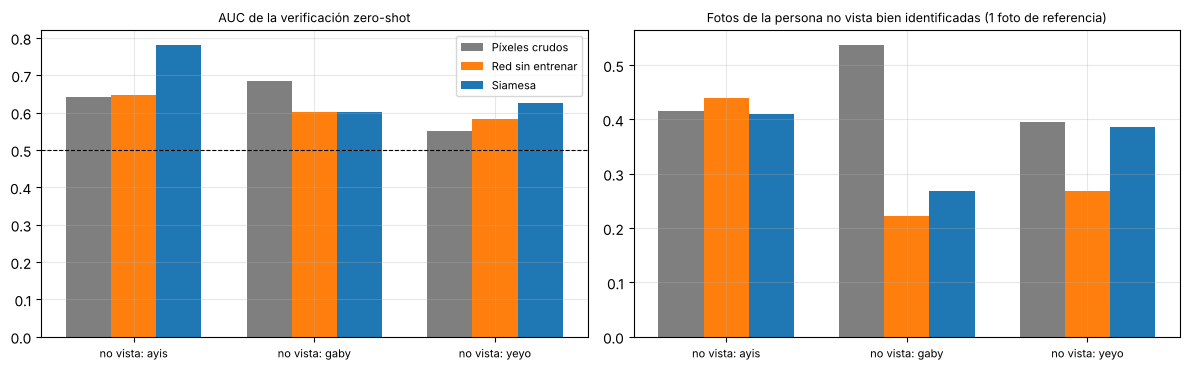

In [14]:
orden = ["Píxeles crudos", "Red sin entrenar", "Siamesa"]
tabla_zs = zs.groupby(["persona no vista", "modelo"])[["auc", "recall_1foto"]].mean().unstack("modelo").round(3)
print("AUC de la verificación zero-shot (promedio de 5 semillas)")
print(tabla_zs["auc"][orden].to_string())
print()
print("Fracción de fotos de la persona no vista identificadas con UNA sola foto de referencia")
print(tabla_zs["recall_1foto"][orden].to_string())
print()
glob_zs = zs.groupby("modelo")[["auc", "recall_1foto"]].agg(["mean", "std"]).loc[orden].round(3)
print("Global (3 personas x 5 semillas)")
print(glob_zs.to_string())

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
ancho = 0.25
for k, (col, titulo, azar) in enumerate([("auc", "AUC de la verificación zero-shot", 0.5), ("recall_1foto", "Fotos de la persona no vista bien identificadas (1 foto de referencia)", None)]):
    for m, (modelo_n, c) in enumerate(zip(orden, ["tab:gray", "tab:orange", "tab:blue"])):
        v = tabla_zs[col][modelo_n].values
        ejes[k].bar(np.arange(3) + (m - 1) * ancho, v, ancho, label=modelo_n, color=c)
    ejes[k].set_xticks(range(3)); ejes[k].set_xticklabels([f"no vista: {p}" for p in PERSONAS], fontsize=8)
    ejes[k].set_title(titulo, fontsize=9)
    if azar: ejes[k].axhline(azar, color="k", ls="--", lw=0.8)
ejes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura del zero-shot.** Es la prueba más exigente y el resultado es negativo, que es lo que cabe esperar:

- **Verificación zero-shot:** el AUC global de la siamesa es **0.671 ± 0.095**, poco más que los píxeles crudos (0.626) y la red sin entrenar (0.611).
  Por persona no vista: ayis 0.781, yeyo 0.627 y gaby 0.603 (igual que la red sin entrenar).
- **Identificación con una foto de la persona no vista:** la siamesa reconoce **35.5 %** de las fotos de la persona nueva, frente a 44.9 % de los píxeles crudos y 31.0 %
  de la red sin entrenar. El azar sería 33.3 %: **no hay evidencia de que la red generalice a personas nuevas**.

La explicación es de datos, no de método. Para que una red siamesa funcione con personas que no vio, tiene que aprender una noción
*general* de parecido facial, y eso requiere ver muchas identidades. Aquí cada red aprende solo con **dos personas** (14 a 20 fotos de
entrenamiento): le alcanza para separar a esas dos entre sí, pero no para construir un espacio de embeddings útil para otras caras. Los sistemas reales entrenan con del orden de millones de
identidades (Schroff et al., 2015). La mejor señal en este taller es la de ayis (0.781), justamente la persona con más fotos y la
que queda como no vista cuando la red entrena con las otras dos.

---

# Conclusiones

1. **La red siamesa aprende.** Con Triplet Loss *batch-all* logra un AUC de verificación de 0.772 ± 0.082 en 10 repartos, frente a 0.62–0.64
   de las referencias sin aprendizaje, y reconoce con una sola foto de referencia el 70 % de las veces (azar: 33 %).
2. **La elección de la minería de tripletas importa más que cualquier otro hiperparámetro.** Con batch-hard, la red colapsó (dispersión 0.006) y no aprendió; con
   batch-all, sí.
3. **Con 38 fotos los resultados son frágiles.** Cambiar qué fotos caen en prueba mueve la exactitud de identificación entre 54 % y 89 %.
   Por eso se reportan promedios y desviaciones y no un solo número.
4. **One-shot y few-shot funcionan en la práctica, aunque con límites:** una referencia basta para superar ampliamente a las referencias sin aprendizaje, pero más fotos de referencia no
   mejoraron el resultado de la siamesa.
5. **Zero-shot no se logró.** Con solo dos identidades de entrenamiento, la red no generaliza a una persona nueva (35.5 % frente a 33.3 % de azar).
6. **Qué mejoraría el sistema:** más fotos por persona y más personas, y sobre todo partir de una red **preentrenada** en reconocimiento facial (por ejemplo FaceNet o
   ArcFace) y ajustarla con las fotos propias, en lugar de entrenar desde cero.

---
## Referencias

- Hermans, A., Beyer, L., y Leibe, B. (2017). *In defense of the triplet loss for person re-identification*. arXiv:1703.07737.
- Koch, G., Zemel, R., y Salakhutdinov, R. (2015). Siamese neural networks for one-shot image recognition. *ICML Deep Learning Workshop*.
- Schroff, F., Kalenichenko, D., y Philbin, J. (2015). FaceNet: A unified embedding for face recognition and clustering. *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, 815–823.
- Zhang, K., Zhang, Z., Li, Z., y Qiao, Y. (2016). Joint face detection and alignment using multitask cascaded convolutional networks. *IEEE Signal Processing Letters, 23*(10), 1499–1503.
- Documentación de PyTorch (pytorch.org), TensorFlow / Keras (keras.io) y scikit-learn (scikit-learn.org).